# El mismo ensemble, otro mecanismo

## AE+CRGN+phys en el parque B, cuando la fusión no gana por ver más sino por ser más estable

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de
Fin de Máster. Sexto de los ocho notebooks y último de los cuatro de explicabilidad, la pareja del
notebook 2 en el otro parque y el cierre del bloque.*

## Resumen

Los notebooks forman dos parejas simétricas por diseño, el mismo modelo individual en ambos parques
(1 y 3) y el mismo ensemble en ambos parques (2 y este). La simetría es deliberada, porque evita
elegir en cada parque lo que mejor quedó, y hace la pregunta interesante. ¿La receta ganadora de C,
es decir, autoencoder más grafo contrastivo más física de coherencia, con fusión z y combinador sin
pesos, funciona en B, y **por el mismo motivo**?

Funciona. La versión B del trío, con el umbral de pares adaptado al parque (phys90max) y el
combinador `max`, rinde CARE-CV 0.6998 ± 0.0064 a 5 semillas y supera al autoencoder de referencia
en 4 de las 5 semillas. La receta *exacta* de C (phys95maxrate) empata a 0.6993, de modo que la elección
de versión ni siquiera importa.

Pero el motivo es **otro**. En C la física era casi ortogonal, con una correlación de 0.035 con el
AE, y aportaba cobertura, es decir, eventos que nadie más veía. En B los pares redundantes
verdaderos no existen, porque sus 2 a 4 pares fuertes son acoplamientos operativos correlacionados
con el AE (0.72), y la fusión no rescata ningún evento. **Gana porque el trío es estable donde el
autoencoder no lo es**, con ±0.006 frente a ±0.029 de varianza multi-semilla. Mismo diseño y dos
mecanismos de victoria distintos, y este notebook analiza el segundo y lo contrasta con el
primero.

## 0. Preparación y verificación

Volcados congelados de los tres miembros en B, donde el CRGN-B multi-semilla se reentrenó
expresamente para esta medición, y réplica de la fusión con las primitivas de campaña. El gate exige
reproducir el CARE-CV versionado de esta semilla, 0.7074.

In [1]:
# Preparacion del entorno comun a los 4 notebooks XAI
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (str(ROOT), str(ROOT / "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
warnings.filterwarnings("ignore")

# ipykernel OutStream no tiene .buffer: evita que el guard utf-8 de los scripts del repo
# (if sys.stdout.encoding != "utf-8": sys.stdout = io.TextIOWrapper(sys.stdout.buffer, ...))
# intente envolverlo al importarlos.
for _s in (sys.stdout, sys.stderr):
    try:
        if getattr(_s, "encoding", None) != "utf-8":
            _s.encoding = "utf-8"
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.xai import (load_ae, load_ae_events, load_meta, load_scores, load_trajdev,
                     load_trajdev_events, trajdev_channel_z)
from src.xai.loaders import DEVICE, ae_scores, trajdev_forecast_errors, trajdev_score
from src.xai.cusum import cusum_series, first_alarm, h_sweep_best, official_cusum
from src.xai import plots as xp
from src.xai.attrib import (ae_integrated_gradients, ae_residual_sensor, occlusion_per_channel,
                            residual_train_stats, trajdev_counterfactual,
                            trajdev_integrated_gradients)
from src.care_official.adapter import OfficialCAREAdapter

xp.set_style()
np.random.seed(42); torch.manual_seed(42)
print(f"ROOT: {ROOT}")
print(f"dispositivo: {DEVICE} | torch {torch.__version__}")

ROOT: .
dispositivo: cuda | torch 2.10.0+cu128


In [2]:
# Los calculos pesados se cachean en results/xai_cache/nb4/
CACHE = ROOT / "results" / "xai_cache" / "nb4"
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """np.savez de dict de arrays; si existe, carga sin recomputar."""
    p = CACHE / f"{name}.npz"
    if p.exists():
        z = np.load(p, allow_pickle=True)
        return {k: z[k] for k in z.files}
    out = fn()
    np.savez_compressed(p, **out)
    return out

print(f"cache: {CACHE}")

cache: .\results\xai_cache\nb4


In [3]:
from src.fusion import combiners as FC
import run_model
from sweep_timeaddm_scoring import ReplayScorer

FARM = "B"
meta = load_meta(FARM)
eids = list(meta.keys())
adapter = OfficialCAREAdapter(raw_path="data/raw/CARE_To_Compare", farm=FARM, window_size=27)
MIEMBROS = ("ae", "crgn", "phys90max")
raw = {d: load_scores(FARM, d) for d in MIEMBROS}

def zparts(dets):
    n_big = max(len(raw[d][0]) for d in dets)
    tr, ev = {}, {}
    for d in dets:
        t, e = raw[d]
        trs = t if len(t) >= n_big else np.repeat(t, -(-n_big // len(t)))[:n_big]
        st = FC.NORMALIZERS["zscore"][0](t)
        tr[d] = FC.NORMALIZERS["zscore"][1](trs, st)
        ev[d] = {k: FC.NORMALIZERS["zscore"][1](v, st) for k, v in e.items()}
    return tr, ev

def fusionar(dets, comb="max"):
    tr, ev = zparts(dets)
    if len(dets) == 1:
        f = lambda zs: zs[0]
    elif comb == "max":
        f = lambda zs: FC.combine_maximum(zs)
    elif comb == "aom":
        f = lambda zs: FC.combine_aom(zs, n_buckets=2)
    elif comb == "avg":
        f = lambda zs: FC.combine_average(zs, [1.0 / len(dets)] * len(dets))
    return f([tr[d] for d in dets]), {e: f([ev[d][e] for d in dets]) for e in eids}

def care_cv(tr_f, ev_f):
    slim = [{"event_id": e, "event_label": meta[e]["event_label"], "asset_id": meta[e]["asset_id"],
             "labels": meta[e]["labels"], "window_timestamps": meta[e]["window_timestamps"],
             "windows": np.empty(0)} for e in eids]
    res = run_model.evaluate(ReplayScorer([tr_f] + [ev_f[e] for e in eids]),
                             np.empty(0), slim, adapter, 42)
    return res["cv"]["care"]

cv_ens = float(cached("gate_care_ensB", lambda: {"care": np.array([care_cv(*fusionar(MIEMBROS, "max"))])})["care"][0])
assert abs(cv_ens - 0.7074) < 2e-3, f"replica no reproduce el ensemble B s42: {cv_ens:.4f}"
print(f"GATE OK — replica ensemble B (zscore+max): CARE-CV {cv_ens:.4f} == committeado 0.7074 "
      f"(media 5 semillas: 0.6998±0.0064, 4/5 vs AE-B honesto)")

GATE OK — replica ensemble B (zscore+max): CARE-CV 0.7074 == committeado 0.7074 (media 5 semillas: 0.6998±0.0064, 4/5 vs AE-B honesto)


## 1. La versión B del campeón

### 1.1 Qué cambia respecto de C y qué no

No cambia nada del diseño, son los mismos tres detectores, la misma z-normalización con train y un
combinador sin pesos. Cambian dos adaptaciones al parque, ambas pre-registradas antes de medir:

1. **El umbral de los pares físicos** baja de 0.95 a 0.90. En B no existen sensores duplicados de
   verdad, porque a |Spearman| ≥ 0.95 solo sobreviven 2 parejas, y son acoplamientos *operativos*
   (anemómetro y velocidad de viento, potencia y sensor de proceso), no redundancia física. A 0.90
   entran 4 pares, igualmente operativos. Esta diferencia estructural del parque es la raíz de todo
   lo que sigue.
2. **El combinador** es `max` en lugar de AOM. Con solo tres miembros y esta estructura de
   correlación fue el mejor de la selección pre-registrada, y la receta exacta de C con
   phys95maxrate y sus 2 pares da 0.6993, un empate que confirma que la elección fina no importa.

### 1.2 El resultado

| Parque B (5 semillas) | CARE-CV | Semilla a semilla vs AE-B |
|---|--:|--:|
| **Ensemble B, AE+CRGN+phys90max (zscore·max)** | **0.6998 ± 0.0064** | **gana 4/5** |
| receta exacta de C (phys95maxrate, avg .5/.25/.25) | 0.6993 ± 0.0065 | gana 4/5 |
| AE-B de referencia | 0.6655 ± 0.0291 | |
| miembros solos, CRGN-B y phys90max | 0.6458 ± 0.0031 y ~0.60 | |

Ocurre lo mismo que con TrajDev-B en el notebook 3. El ensemble pierde
**únicamente** contra la semilla afortunada del autoencoder, que es la del despliegue con 0.7211, y
gana las otras cuatro. En la semilla que se usa para exponer los casos, por tanto, el AE va *por
delante*, y así hay que leer todo lo que este notebook muestra evento a evento. La victoria 4/5 vive
en el agregado multi-semilla.

## 2. El mecanismo, ortogonalidad en C y estabilidad en B

### 2.1 Las correlaciones, lado a lado

En C, phys casi no se parecía a nadie, con 0.035 frente al AE, de modo que cada miembro veía fallos
propios. En B:

In [4]:
cat = {d: np.concatenate([raw[d][1][e] for e in eids]) for d in MIEMBROS}
corr_b = pd.DataFrame({a: {b: np.corrcoef(cat[a], cat[b])[0, 1] for b in MIEMBROS} for a in MIEMBROS})
print("correlaciones B (score de test):")
print(corr_b.round(3).to_string())
print("\nreferencia C (notebook 2): ae-crgn 0.42 | ae-phys 0.035 | crgn-phys 0.039")
print(f"en B: ae-phys {corr_b.loc['ae','phys90max']:.3f}")

correlaciones B (score de test):
              ae   crgn  phys90max
ae         1.000  0.486      0.725
crgn       0.486  1.000      0.504
phys90max  0.725  0.504      1.000

referencia C (notebook 2): ae-crgn 0.42 | ae-phys 0.035 | crgn-phys 0.039
en B: ae-phys 0.725


### 2.2 Cinco semillas, cuatro detectores

Si la física de B no aporta cobertura nueva, ¿de dónde sale el 4/5? De la **varianza**. El
autoencoder de B es inestable entre semillas de entrenamiento, con un CARE-CV que oscila entre 0.64
y 0.72, mientras que CRGN y phys son casi invariantes (±0.003 y ±0.000, porque phys ni siquiera
tiene semilla). El ensemble hereda esa estabilidad, de modo que cuando el AE cae a 0.64, el trío lo
sostiene en ~0.69-0.70. La fusión funciona aquí como un **estabilizador**, no como un ampliador de
cobertura.

AE-B (honesto)     0.6655 ± 0.0291  [0.7211, 0.6597, 0.641, 0.643, 0.6627]
CRGN-B             0.6458 ± 0.0031  [0.6497, 0.6473, 0.6415, 0.6476, 0.6427]
phys90max          0.6004 ± 0.0022  [0.604, 0.6, 0.6014, 0.5992, 0.5976]
ensemble (max)     0.6998 ± 0.0064  [0.7074, 0.705, 0.7008, 0.6893, 0.6966]

pareado por semilla: ensemble gana 4/5 (pierde solo s42)


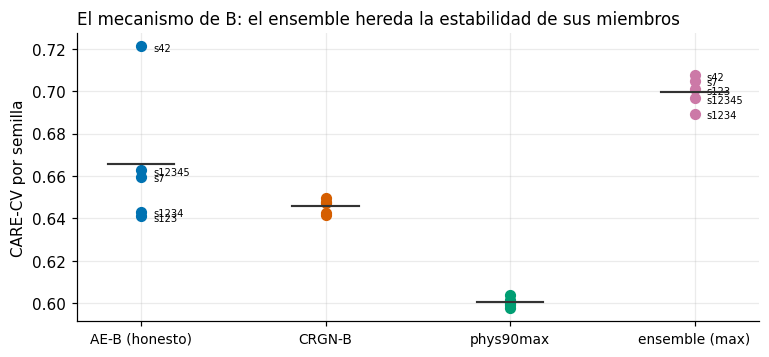

In [5]:
d5 = json.load(open(ROOT / "results/tables/fuse_b5s_aecrgn_phys90max_b.json"))
seeds5 = d5["seeds"]
series = {"AE-B (honesto)": d5["baselines"]["ae"]["seeds"],
          "CRGN-B": d5["baselines"]["crgn"]["seeds"],
          "phys90max": d5["baselines"]["phys90max"]["seeds"],
          "ensemble (max)": next(r["seeds"] for r in d5["fusions"] if r["config"] == "zscore|max")}
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (name, vals) in enumerate(series.items()):
    ax.scatter([i] * len(vals), vals, s=40, color=xp.PALETTE[i], zorder=3)
    for s, v in zip(seeds5, vals):
        if name in ("AE-B (honesto)", "ensemble (max)"):
            ax.annotate(f"s{s}", (i, v), xytext=(8, -3), textcoords="offset points", fontsize=6.5)
    ax.plot([i - 0.18, i + 0.18], [np.mean(vals)] * 2, color="#333333", lw=1.4, zorder=4)
ax.set_xticks(range(len(series))); ax.set_xticklabels(series.keys(), fontsize=9)
ax.set_ylabel("CARE-CV por semilla")
ax.set_title("El mecanismo de B: el ensemble hereda la estabilidad de sus miembros", loc="left")
for name, vals in series.items():
    print(f"{name:ie<0}" if False else f"{name:18} {np.mean(vals):.4f} ± {np.std(vals):.4f}  {vals}")
wins = sum(1 for a, f in zip(series["AE-B (honesto)"], series["ensemble (max)"]) if f > a)
print(f"\npareado por semilla: ensemble gana {wins}/5 (pierde solo s42)")

## 3. Cobertura, nada que rescatar y algo que adelantar

### 3.1 Las seis anomalías

En C el trío rescataba eventos. En B no hay nada que rescatar, porque las seis anomalías las ven
todos los miembros por separado, como vimos en el notebook 3. El mapa muestra las antelaciones, y la
mejora posible aquí es de *tiempo*, no de cobertura.

anomalias donde el ensemble adelanta >24 h al AE:
   ev34: AE 303 h -> ensemble 513 h (+210)
   ev27: AE 1384 h -> ensemble 1428 h (+45)
   ev77: AE 1348 h -> ensemble 1475 h (+126)


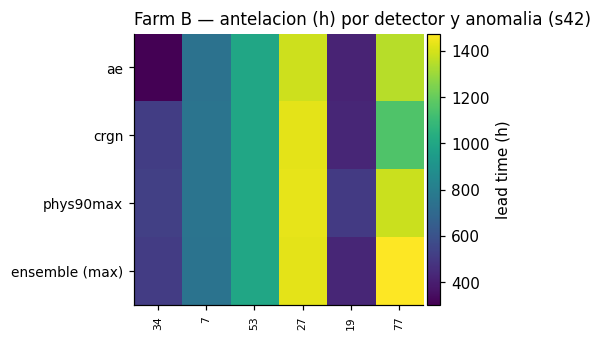

In [6]:
def _sweep_cfg(name, dets, comb):
    tr_f, ev_f = fusionar(dets, comb)
    best = h_sweep_best(tr_f, ev_f, meta, adapter)
    out = {f"S_{e}": v for e, v in best.pop("ev_S").items()}
    out["params"] = np.array([best["care"], best["h"], best["h_scale"], best["cov"], best["earl"],
                              best["rel"], best["acc"], best["mu"], best["k"], best["h_base"]])
    return out

CONFIGS = {"ae": (("ae",), "max"), "crgn": (("crgn",), "max"), "phys90max": (("phys90max",), "max"),
           "ensemble (max)": (MIEMBROS, "max")}
SW = {}
for name, (dets, comb) in CONFIGS.items():
    sw = cached(f"sweep_{name.replace(' ', '_').replace('(', '').replace(')', '')}",
                lambda dets=dets, comb=comb: _sweep_cfg(name, dets, comb))
    SW[name] = {"params": sw["params"], "ev_S": {e: sw[f"S_{e}"] for e in eids}}

anoms = [e for e in eids if meta[e]["event_label"] == "anomaly"]
normales = [e for e in eids if meta[e]["event_label"] != "anomaly"]

def leads_de(sw):
    out = {}
    for e in anoms:
        S, h = sw["ev_S"][e], sw["params"][1]
        lab = np.asarray(meta[e]["labels"], bool)
        idx = first_alarm(S, h)
        out[e] = None if idx is None else (meta[e]["window_timestamps"][np.flatnonzero(lab)[-1]] -
                                           meta[e]["window_timestamps"][idx]).total_seconds() / 3600.0
    return out

LEADS = {n: leads_de(sw) for n, sw in SW.items()}
mat = pd.DataFrame(LEADS).T[anoms]
xp.plot_coverage_matrix(mat, title="Farm B — antelacion (h) por detector y anomalia (s42)")
mejoras = {e: (LEADS["ae"][e], LEADS["ensemble (max)"][e]) for e in anoms
           if LEADS["ensemble (max)"][e] - LEADS["ae"][e] > 24}
print("anomalias donde el ensemble adelanta >24 h al AE:")
for e, (a, c) in mejoras.items():
    print(f"   ev{e}: AE {a:.0f} h -> ensemble {c:.0f} h (+{c-a:.0f})")

### 3.2 Las falsas alarmas, que el ensemble tampoco arregla

La otra cara, imprescindible tras el notebook 3. En los 9 periodos normales, ¿mejora el trío el
silencio del autoencoder?

In [7]:
fa = {}
for name, sw in SW.items():
    h = sw["params"][1]
    fa[name] = {e: float(sw["ev_S"][e].max() / h) for e in normales}
df_fa = pd.DataFrame(fa).round(2)
n_fa = {n: int((df_fa[n] > 1).sum()) for n in fa}
print(f"normales con falsa alarma (margen>1): {n_fa} de {len(normales)}")
df_fa

normales con falsa alarma (margen>1): {'ae': 5, 'crgn': 9, 'phys90max': 9, 'ensemble (max)': 6} de 9


,ae,crgn,phys90max,ensemble (max)
83,14.69,48.91,60.99,40.44
52,0.22,5.61,4.16,0.92
21,0.18,1.19,4.39,0.47
2,0.56,1.42,6.82,0.91
23,1.35,5.34,5.12,2.04
87,5.51,14.00,9.12,6.06
74,1.59,10.83,19.72,4.76
86,0.99,3.65,9.45,2.91
82,2.30,14.85,12.49,6.89


No. El ensemble hereda la mayoría de las falsas alarmas del parque, porque sus miembros ruidosos,
CRGN y phys, disparan en casi todos los normales y no dejan callar al conjunto. La ganancia del
ensemble B no está en los eventos individuales de esta semilla, está en la resistencia del agregado
multi-semilla que muestra la figura del apartado 2.2.

## 4. ev34, doscientas horas más de aviso

Es la única mejora clara por evento del trío en B. El autoencoder ve ev34 con 303 h, CRGN y phys lo
ven con ~516-524 h, y el ensemble hereda 513 h, es decir, **+210 horas de margen de planificación**,
nueve días. Vemos qué miembro domina en cada tramo, y la instancia física de qué par operativo se
descuelga.

instancia de la alarma (2023-08-24 14:40:00): z_ae = 3.1 | z_crgn = 1.8 | z_phys90max = 2.5
leads ev34: AE 303 h | crgn 516 | phys 524 | ensemble 513


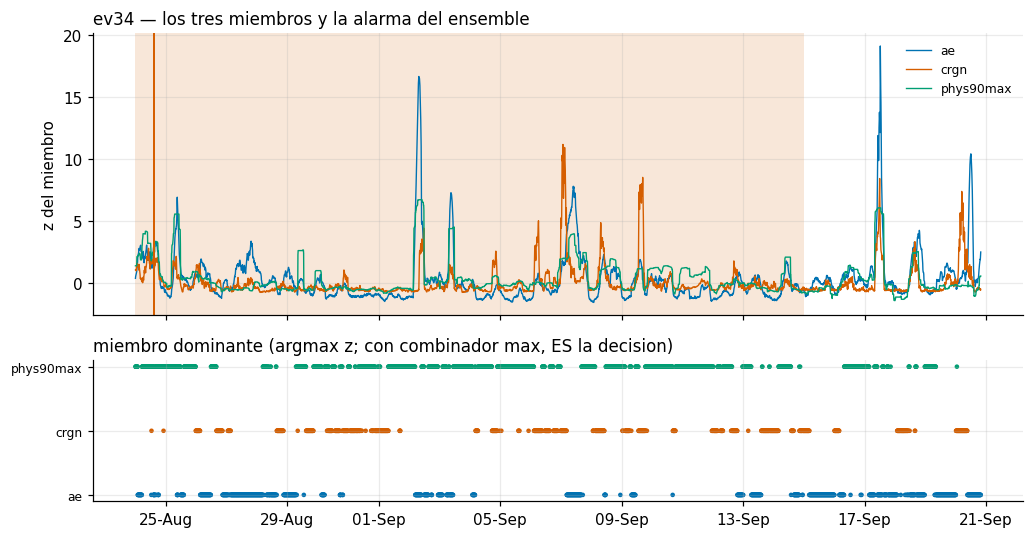

In [8]:
e = 34
m = meta[e]
trz, evz = zparts(MIEMBROS)
zs = {d: evz[d][e] for d in MIEMBROS}
sw_c = SW["ensemble (max)"]
idx = first_alarm(sw_c["ev_S"][e], sw_c["params"][1])
from src.xai.plots import _shade_anomaly
import matplotlib.dates as mdates
fig, axes = plt.subplots(2, 1, figsize=(9.5, 5), sharex=True, height_ratios=[2, 1])
_shade_anomaly(axes[0], m["window_timestamps"], m["labels"])
for i, d in enumerate(MIEMBROS):
    axes[0].plot(m["window_timestamps"], zs[d], lw=0.9, color=xp.PALETTE[i], label=d)
if idx is not None:
    axes[0].axvline(m["window_timestamps"][idx], color="#D55E00", lw=1.3)
axes[0].legend(fontsize=8); axes[0].set_ylabel("z del miembro")
axes[0].set_title("ev34 — los tres miembros y la alarma del ensemble", loc="left")
dom = np.argmax(np.vstack([zs[d] for d in MIEMBROS]), axis=0)
axes[1].scatter(m["window_timestamps"], dom, c=[xp.PALETTE[i] for i in dom], s=4)
axes[1].set_yticks(range(3)); axes[1].set_yticklabels(MIEMBROS, fontsize=8)
axes[1].set_title("miembro dominante (argmax z; con combinador max, ES la decision)", loc="left")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
plt.tight_layout()
if idx is not None:
    print(f"instancia de la alarma ({m['window_timestamps'][idx]}): " +
          " | ".join(f"z_{d} = {float(zs[d][idx]):.1f}" for d in MIEMBROS))
print(f"leads ev34: AE {LEADS['ae'][e]:.0f} h | crgn {LEADS['crgn'][e]:.0f} | phys {LEADS['phys90max'][e]:.0f} "
      f"| ensemble {LEADS['ensemble (max)'][e]:.0f}")

### 4.1 La instancia física, ¿se descuelga el par operativo?

Los pares de phys en B son acoplamientos de operación (potencia y sensor de proceso, anemómetro y
velocidad). En C, la instancia física del rescate del notebook 2 era inequívoca, un par redundante
rompiéndose. La pregunta aquí es si en B existe ese momento, y la respuesta que documenta la figura
es que **apenas**. El par principal sigue correlacionado casi igual en el tramo anómalo
(0.81 --> 0.79), y el z de phys en la ventana de alarma es modesto, 2.5 frente al 94 de la instancia
de C. El aporte de la física en B no es una ruptura de coherencia sino un **aviso anticipado** del
mismo deterioro que el AE ve después, coherente con su correlación de 0.72 con el AE y con el
mecanismo de estabilidad del apartado 2. Que esta instancia sea tan poco espectacular es
precisamente lo que separa los dos parques.

correlacion del par: tramo inicial 0.808 -> tramo anomalo 0.789


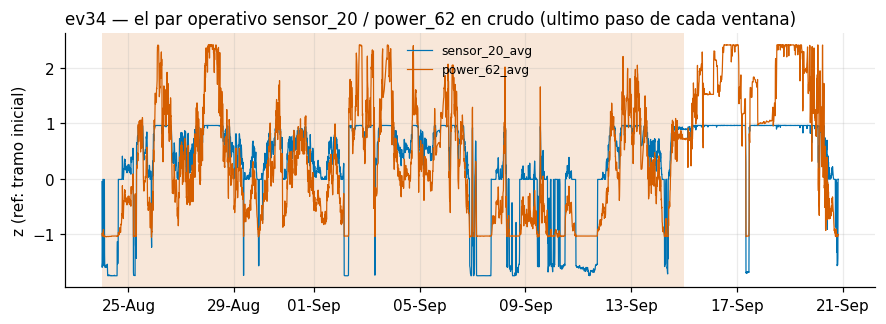

In [9]:
aev = {x["event_id"]: x for x in load_ae_events(FARM)}[34]
feats_b = load_ae(FARM)["feats"]
try:
    i20 = [i for i, f in enumerate(feats_b) if "sensor_20" in f][0]
    i62 = [i for i, f in enumerate(feats_b) if "power_62" in f][0]
except IndexError:
    i20, i62 = 0, 1
fig, ax = plt.subplots(figsize=(9.5, 3))
_shade_anomaly(ax, aev["window_timestamps"], aev["labels"])
a = aev["raw"][:, -1, i20]; b = aev["raw"][:, -1, i62]
za = (a - np.nanmean(a[:400])) / (np.nanstd(a[:400]) + 1e-8)
zb = (b - np.nanmean(b[:400])) / (np.nanstd(b[:400]) + 1e-8)
ax.plot(aev["window_timestamps"], za, lw=0.8, label=feats_b[i20])
ax.plot(aev["window_timestamps"], zb, lw=0.8, label=feats_b[i62])
ax.legend(fontsize=8); ax.set_ylabel("z (ref: tramo inicial)")
ax.set_title("ev34 — el par operativo sensor_20 / power_62 en crudo (ultimo paso de cada ventana)", loc="left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
corr_norm = np.corrcoef(za[:400], zb[:400])[0, 1]
lab = np.asarray(meta[34]["labels"], bool)
corr_anom = np.corrcoef(za[lab], zb[lab])[0, 1]
print(f"correlacion del par: tramo inicial {corr_norm:.3f} -> tramo anomalo {corr_anom:.3f}")

## 5. Shapley en B, el reparto bajo otro mecanismo

Mismo protocolo exacto que en C, con 8 coaliciones, z más max para |S| ≥ 2, y el CARE del barrido.
Conviene recordar la lectura del apartado 1.2, porque en esta semilla el AE está en su pico y su φ
saldrá inflado respecto del agregado multi-semilla. El interés está en la *forma* del reparto
comparada con C.

In [10]:
from itertools import combinations
import math

def _coaliciones():
    out = {}
    for r in (1, 2, 3):
        for S in combinations(MIEMBROS, r):
            tr_f, ev_f = fusionar(S, "max")
            best = h_sweep_best(tr_f, ev_f, meta, adapter)
            out["|".join(S)] = best["care"]
    return {"vals": np.array(list(out.values())), "keys": np.array(list(out.keys()))}

co = cached("coaliciones_care_b", _coaliciones)
V = {tuple(sorted(k.split("|"))): float(v) for k, v in zip(co["keys"], co["vals"])}
V[()] = 0.0
phi = {}
for i in MIEMBROS:
    s = 0.0
    resto = [d for d in MIEMBROS if d != i]
    for r in range(len(resto) + 1):
        for S in combinations(resto, r):
            w = math.factorial(len(S)) * math.factorial(len(MIEMBROS) - len(S) - 1) / math.factorial(len(MIEMBROS))
            s += w * (V[tuple(sorted(S + (i,)))] - V[tuple(sorted(S))])
    phi[i] = s
print("CARE test-tuned (s42) por coalicion:")
for k in sorted(V, key=len):
    if k: print(f"   {{{', '.join(k)}}}: {V[k]:.4f}")
print("\nShapley B (s42):")
for d, v in phi.items():
    print(f"   phi_{d} = {v:.4f} ({100*v/sum(phi.values()):.0f}%)")
print("\nreferencia C (notebook 2): ae 38% / crgn 33% / phys 29%")

CARE test-tuned (s42) por coalicion:
   {ae}: 0.7211
   {crgn}: 0.6533
   {phys90max}: 0.6280
   {ae, crgn}: 0.7185
   {ae, phys90max}: 0.7122
   {crgn, phys90max}: 0.6865
   {ae, crgn, phys90max}: 0.7189

Shapley B (s42):
   phi_ae = 0.2760 (38%)
   phi_crgn = 0.2293 (32%)
   phi_phys90max = 0.2135 (30%)

referencia C (notebook 2): ae 38% / crgn 33% / phys 29%


El reparto porcentual de B (38/32/30) es casi idéntico al de C (38/33/29), y sin embargo los
mecanismos son opuestos. La diferencia está en los **valores de las coaliciones**, no en los φ.

En C las coaliciones *escalan* (0.743 --> 0.755 --> 0.775, y el marginal de phys sobre la pareja es
+0.020), de modo que los miembros son **complementarios**. En B son **planas**, porque el AE solo,
en su semilla más alta, ya hace 0.7211 y el trío 0.7189, con un marginal de phys sobre la pareja de
+0.0004, de modo que los miembros son **sustitutos** y se cubren entre sí más que sumarse.

Un Shapley plano de sustitutos reparte en proporciones parecidas a un Shapley de complementarios, y
de ahí que haya que mirar siempre la tabla de coaliciones junto a los porcentajes. Y de nuevo, esto
es la semilla que el ensemble pierde, mientras que el 4/5 multi-semilla del apartado 2.2 es el
resultado.

## 6. Conclusiones y limitaciones

Con este notebook se cierra el bloque de explicabilidad. El trabajo midió el mismo modelo y el mismo
ensemble en dos parques deliberadamente distintos, y la explicabilidad permite decir no solo *cuánto*
rinden sino *por qué*.

| | Parque C (limpio, 27 fallos variados) | Parque B (ruidoso, 6 fallos, un modo dominante) |
|---|---|---|
| El fallo típico | Precursor de canal único o grupo pequeño, trazable | Precursor difuso entre muchos canales, hasta en la mejor detección |
| El reto | Cobertura y antelación | Callar en los periodos normales |
| phys | Casi ortogonal (0.035), ve fallos propios | Aviso anticipado del AE (0.72), no ve nada nuevo |
| Por qué gana el ensemble | **Cobertura**, rescata eventos (ev15, ev76) y antelaciones | **Estabilidad**, ±0.006 donde el AE oscila ±0.029 |
| El resultado | 0.7694 ± 0.007, 5/5 | 0.6998 ± 0.0064, 4/5 |

1. **La fusión a nivel de score no tiene una sola virtud.** El mismo diseño compra cobertura donde
   hay física complementaria y compra varianza donde no la hay. Ambas cosas se pagan en la métrica y
   ambas son deseables en operación.
2. **El techo de B no es un fracaso de modelado sino una propiedad del parque.** Ronda 0.70-0.72
   para todo lo probado, modelos, palancas anti-ruido, representaciones y fusiones, con el mapa
   completo a 5 semillas. La anatomía de sus falsas alarmas del notebook 3 muestra a qué se parece
   por dentro.

**Limitaciones.**

1. Los análisis por evento usan, para dibujar, el punto de operación que da el mejor CARE del
   barrido, es decir, el umbral elegido con las etiquetas a la vista. Las decisiones del trabajo son
   CARE-CV multi-semilla.
2. Con 6 anomalías y 9 periodos normales, cada celda de los mapas de B pesa mucho, y por eso
   ninguna conclusión de este notebook se apoya en un solo evento.
3. La semilla que se usa para exponer los casos es la única que el ensemble pierde frente al
   autoencoder, de modo que las figuras por evento muestran el escenario menos favorable.

## Referencias

- Gück, C., Roelofs, C. M. A., Faulstich, S. (2024). *CARE to Compare: A Real-World Benchmark
  Dataset for Early Fault Detection in Wind Turbine Data.* Data, 9(12), 138.
- Takeishi, N., Kawahara, Y. (2023). *A Characteristic Function for Shapley-Value-Based Attribution
  of Anomaly Scores.* Transactions on Machine Learning Research.
- Levy, E., et al. (2026). *Analyzing SHAP to Understand Anomaly Detection Algorithm Behaviors and
  Their Complementarity.* IDA 2026.
- Roelofs, C. M. A., Lutz, M.-A., Faulstich, S., Vogt, S. (2021). *Autoencoder-based anomaly root
  cause analysis for wind turbines* (ARCANA). Energy and AI, 4, 100065.
- Alcalá, C. F., Qin, S. J. (2009). *Reconstruction-based contribution for process monitoring.*
  Automatica, 45(7).
- Aggarwal, C. C., Sathe, S. (2017). *Outlier Ensembles: An Introduction.* Springer.